# 01 - Raw data overview

First look at the lap table built by `python -m f1lab.ingest`: 2022 from FastF1,
2023-2025 from OpenF1. Goal: understand what is in it and what must be cleaned
before modelling. No cleaning is done here; that comes next.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
df = pd.read_parquet("../data/laps.parquet")
df["race"] = df["season"].astype(str) + "-" + df["round"].astype(str)
df.shape

(100701, 16)

## Coverage

In [2]:
df.groupby(["season", "source"]).agg(
    races=("race", "nunique"), laps=("lap_number", "size"), drivers=("driver", "nunique")
)

,,races,laps,drivers
season,source,,,
2022,fastf1,22,23577,22
2023,openf1,22,24361,22
2024,openf1,24,26561,24
2025,openf1,24,26202,21


22, 22, 24 and 24 races match the real calendars (2023 lost Imola to flooding;
OpenF1 still lists it but has no data, so it is excluded).

## Missing values

In [3]:
missing = df.isna().sum()
missing[missing > 0]

lap_time_s    555
tyre_age      520
dtype: int64

In [4]:
# where do the missing lap times come from?
no_time = df["lap_time_s"].isna()
special = df["is_pit_in"] | df["is_pit_out"] | (df["lap_number"] == 1)
print(f"missing lap times: {no_time.sum()} ({no_time.mean():.1%})")
print(f"  on pit-in, pit-out or lap-1 rows: {(no_time & special).sum()}")
print(f"  elsewhere: {(no_time & ~special).sum()}")
print("missing tyre_age by season:", df[df['tyre_age'].isna()].groupby('season').size().to_dict())

missing lap times: 555 (0.6%)
  on pit-in, pit-out or lap-1 rows: 193
  elsewhere: 362
missing tyre_age by season: {2022: 520}


Every missing `tyre_age` is a FastF1 2022 row. About a third of the missing lap
times are pit or lap-1 rows; the rest are laps that were never timed (red flags,
retirements).

## What a normal lap looks like

In [5]:
# compare each lap to the median lap of its own race, so tracks are comparable
clean_pace = ~df["is_pit_in"] & ~df["is_pit_out"]
race_median = df[clean_pace].groupby("race")["lap_time_s"].transform("median")
df["rel"] = df["lap_time_s"] / race_median
df["rel"].describe(percentiles=[0.05, 0.5, 0.9, 0.95, 0.99]).round(3)

count    93678.000
mean         1.023
std          0.101
min          0.853
5%           0.973
50%          1.000
90%          1.036
95%          1.185
99%          1.568
max          1.918
Name: rel, dtype: float64

laps that are not pit, lap 1, rain or untimed: 88718 (88.1%)


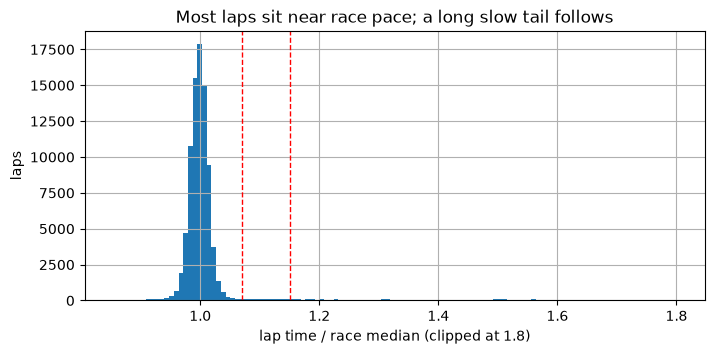

normal laps slower than 1.07x race median: 5.9%
normal laps slower than 1.15x race median: 4.6%


In [6]:
normal = clean_pace & (df["lap_number"] > 1) & ~df["rainfall"] & df["lap_time_s"].notna()
print(f"laps that are not pit, lap 1, rain or untimed: {normal.sum()} ({normal.mean():.1%})")

fig, ax = plt.subplots(figsize=(8, 3.5))
df.loc[normal, "rel"].clip(upper=1.8).hist(bins=120, ax=ax)
for x in (1.07, 1.15):
    ax.axvline(x, color="red", ls="--", lw=1)
ax.set_xlabel("lap time / race median (clipped at 1.8)")
ax.set_ylabel("laps")
ax.set_title("Most laps sit near race pace; a long slow tail follows")
plt.show()

for cut in (1.07, 1.15):
    print(f"normal laps slower than {cut}x race median: {(df.loc[normal, 'rel'] > cut).mean():.1%}")

The bulk of laps are within a few percent of race pace, then there is a long
slow tail: about 6% of otherwise ordinary laps are more than 7% slower than the
race median. That is far more than traffic alone explains, so these are very
likely safety-car, virtual-safety-car and red-flag laps. The lap table has no
track-status column yet, so that needs to come from the race-control data.

## Rows that behave differently

In [7]:
rows = {
    "lap 1": df["lap_number"] == 1,
    "rain": df["rainfall"],
    "pit-in": df["is_pit_in"],
    "pit-out": df["is_pit_out"],
}

def median_rel(mask):
    rel = df.loc[mask, "rel"].dropna()
    return round(rel.median(), 3) if len(rel) else "n/a"

pd.DataFrame(
    {
        name: {"rows": int(m.sum()), "share": f"{m.mean():.1%}", "median rel": median_rel(m)}
        for name, m in rows.items()
    }
).T

,rows,share,median rel
lap 1,1756,1.7%,1.108
rain,3986,4.0%,1.027
pit-in,3397,3.4%,n/a
pit-out,3409,3.4%,n/a


Lap 1 is about 11% slower than race pace (standing start, traffic), so it
cannot be used to learn tyre behaviour. Pit-in and pit-out rows have no relative
time here because they are excluded from the race median by construction; they
are slow for reasons unrelated to pace and will be dropped for the lap-time
model. Rain affects 4% of laps, concentrated in a handful of races.

In [8]:
rain_share = df.groupby("race")["rainfall"].mean()
print("races where more than 20% of laps are in rain:", (rain_share > 0.2).sum())
df.groupby("season")["compound"].value_counts(normalize=True).unstack().round(3)

races where more than 20% of laps are in rain: 8


compound,HARD,INTERMEDIATE,MEDIUM,None,SOFT,WET
season,,,,,,
2022,0.341,0.061,0.390,0.014,0.177,0.016
2023,0.486,0.030,0.340,NaN,0.142,0.002
2024,0.518,0.082,0.334,NaN,0.066,0.001
2025,0.414,0.050,0.409,NaN,0.126,NaN


Intermediates and wets make up a small but real share and behave nothing like
slicks, so the first model will be slick-only. In 2022 about 1.4% of laps (334) have
the literal string `"None"` as compound (the `None` column), not a true missing value. 268 of them
also lack `tyre_age`, which is missing on 520 rows in total, so the two gaps overlap but are not the same rows.

Tyre age can look absurd (79 laps at Monaco 2024), but it is real: a lap-1 red
flag allowed free tyre changes and most drivers then ran one hard set to the end,
and `tyre_age` includes laps done in earlier sessions.

## Cleaning rules to implement next
1. Drop pit-in, pit-out and lap-1 rows.
2. Drop untimed laps (no lap time).
3. Keep only slick compounds (SOFT, MEDIUM, HARD) and dry laps for the first model.
4. Drop safety-car, VSC and red-flag laps. Needs race-control data; until then a
   per-race pace threshold is a stopgap.
5. Convert the 2022 compound string `"None"` to a real missing value, and handle the
   missing 2022 `tyre_age` (FastF1) explicitly instead of silently.